In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, classification_report 
from sklearn.linear_model import LogisticRegression


In [2]:
# sigmoid function used to map any real value between 0 and 1
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [3]:
def logistic_prediction(x,w,b):
    z=w@(x.T)+b
    return sigmoid(z)

In [4]:
def classify(probabilities):
   return np.where(probabilities>=0.5,1,0)

In [5]:
# cost function for logistic regression is called the log loss function or cross-entropy loss function
def compute_cost_logistic(x,y,w,b):
    m=x.shape[0]
    f_wb=logistic_prediction(x,w,b)
    cost=-np.sum(y*np.log(f_wb)+(1-y)*np.log(1-f_wb))/m
    return cost


In [6]:
def compute_gradient_logistic(x,y,w,b):
    m=x.shape[0]
    f_wb=logistic_prediction(x,w,b)
    error=f_wb-y
    dj_dw=(1/m)*(error@x)
    dj_db=(1/m)*np.sum(error)
    return dj_dw,dj_db
    

In [7]:
def gradient_descent_logistic(x,y,w,b,alpha,iterations):
    cost_history=[]
    for i in range(iterations):
        dj_dw,dj_db=compute_gradient_logistic(x,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        cost=compute_cost_logistic(x,y,w,b)
        cost_history.append(cost)
    return w,b,cost_history
    

In [8]:
df=pd.read_csv('wdbc.data',header=None)
print(df.head())
print(df.shape)

         0  1      2      3       4       5        6        7       8   \
0    842302  M  17.99  10.38  122.80  1001.0  0.11840  0.27760  0.3001   
1    842517  M  20.57  17.77  132.90  1326.0  0.08474  0.07864  0.0869   
2  84300903  M  19.69  21.25  130.00  1203.0  0.10960  0.15990  0.1974   
3  84348301  M  11.42  20.38   77.58   386.1  0.14250  0.28390  0.2414   
4  84358402  M  20.29  14.34  135.10  1297.0  0.10030  0.13280  0.1980   

        9   ...     22     23      24      25      26      27      28      29  \
0  0.14710  ...  25.38  17.33  184.60  2019.0  0.1622  0.6656  0.7119  0.2654   
1  0.07017  ...  24.99  23.41  158.80  1956.0  0.1238  0.1866  0.2416  0.1860   
2  0.12790  ...  23.57  25.53  152.50  1709.0  0.1444  0.4245  0.4504  0.2430   
3  0.10520  ...  14.91  26.50   98.87   567.7  0.2098  0.8663  0.6869  0.2575   
4  0.10430  ...  22.54  16.67  152.20  1575.0  0.1374  0.2050  0.4000  0.1625   

       30       31  
0  0.4601  0.11890  
1  0.2750  0.08902  
2  0.

In [9]:
print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df[1].value_counts())


Missing values:
0

Target distribution:
1
B    357
M    212
Name: count, dtype: int64


In [10]:
X=df.iloc[:,2:].to_numpy()
y=(df[1]=='M').astype(int).to_numpy()
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique labels:", np.unique(y))
print("Malignant cases:", np.sum(y == 1))
print("Benign cases:", np.sum(y == 0))



X shape: (569, 30)
y shape: (569,)
Unique labels: [0 1]
Malignant cases: 212
Benign cases: 357


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (455, 30)
Test set shape: (114, 30)


In [12]:
# feature normalization
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
X_train_norm = (X_train - mean) / (std)
X_test_norm = (X_test - mean) / (std)
print("Normalized training shape:", X_train_norm.shape)
print("Normalized testing shape:", X_test_norm.shape)

Normalized training shape: (455, 30)
Normalized testing shape: (114, 30)


In [13]:
alpha = 0.001
iterations = 10000
w=np.zeros(X_train_norm.shape[1])
b=0

w, b, cost_history = gradient_descent_logistic(
    X_train_norm,
    y_train,
    w,
    b,
    alpha,
    iterations
)

print("Trained weights:", w)
print("Trained bias:", b)
print("Initial cost:", cost_history[0])
print("Final cost:", cost_history[-1])

Trained weights: [ 0.37464463  0.3544037   0.37103429  0.37084914  0.14935018  0.12775279
  0.28893607  0.39648902  0.09586502 -0.14924481  0.32722732  0.00843242
  0.27444764  0.29427717  0.00148997 -0.11518872 -0.09040832  0.04503243
 -0.0722634  -0.19235462  0.44310331  0.43315637  0.42311407  0.41794737
  0.29958127  0.20632437  0.28829805  0.3972499   0.30724831  0.09065925]
Trained bias: -0.35468879334434883
Initial cost: 0.6911984606919467
Final cost: 0.10711235334123624


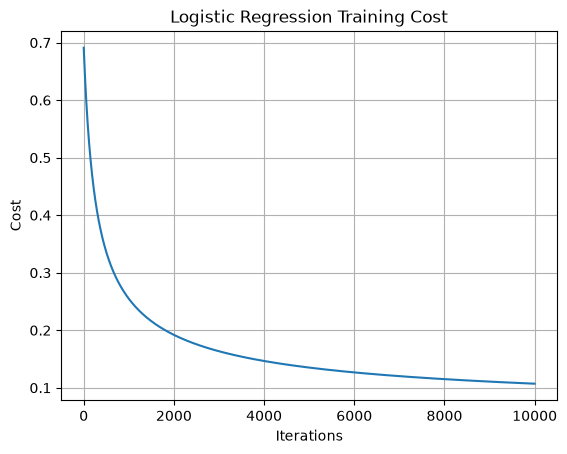

In [14]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Logistic Regression Training Cost")
plt.grid()
plt.show()

In [15]:
# Calculate probabilities
y_prob = logistic_prediction(X_test_norm, w, b)

# Convert probabilities into class predictions
y_pred = classify(y_prob)

print("First 10 probabilities:")
print(y_prob[:10])

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nActual labels:")
print(y_test[:10])

First 10 probabilities:
[0.20016816 0.99577013 0.93533177 0.03807148 0.00886705 0.9999983
 0.99997675 0.86911556 0.50127876 0.02392087]

First 10 predictions:
[0 1 1 0 0 1 1 1 1 0]

Actual labels:
[0 1 1 0 0 1 1 1 0 0]


In [16]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.9824561403508771
Precision: 0.9767441860465116
Recall: 0.9767441860465116
F1 Score: 0.9767441860465116


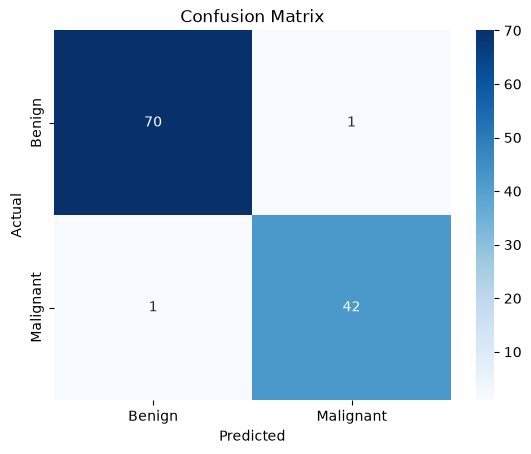

In [17]:
# confusion matrix is used to evaluate the performance of a classification model by comparing the predicted labels with the actual labels. It provides a summary of the number of correct and incorrect predictions for each class, allowing us to assess the model's accuracy and identify any potential issues with misclassification.
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

The results show:

True Negative (70): The model correctly classified 70 benign cases.

True Positive (42): The model correctly classified 42 malignant cases.

False Positive (1): The model incorrectly classified 1 benign case as malignant.

False Negative (1): The model incorrectly classified 1 malignant case as benign.

Out of 114 test observations, the model correctly classified 112 and incorrectly classified 2.

The resulting accuracy is approximately 98.25%.

In [18]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99        71
   Malignant       0.98      0.98      0.98        43

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Logistic Regression Using Scikit-learn

In [21]:
sk_model = LogisticRegression(max_iter=10000)

sk_model.fit(X_train_norm, y_train)

sk_pred = sk_model.predict(X_test_norm)

In [22]:
print("First 10 predictions:", sk_pred[:10])
print("Actual labels:", y_test[:10])

First 10 predictions: [0 1 1 0 0 1 1 1 0 0]
Actual labels: [0 1 1 0 0 1 1 1 0 0]


In [23]:
print("Accuracy:", accuracy_score(y_test, sk_pred))
print("Precision:", precision_score(y_test, sk_pred))
print("Recall:", recall_score(y_test, sk_pred))
print("F1 Score:", f1_score(y_test, sk_pred))

Accuracy: 0.9736842105263158
Precision: 0.9761904761904762
Recall: 0.9534883720930233
F1 Score: 0.9647058823529412
